In [1]:
# =============================
# 1. Import libraries
# =============================
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# =============================
# 2. Load data
# =============================
file_path = "/mnt/f/Solar-Review-Ppaer/Monthwise-Data-Sheets/Data_clean/10-Minute-Average-Data/10-min-AVG-Data-miss.xlsx"
df = pd.read_excel(file_path)
df = df[['DateTime', 'Power_MW']]
df['Power_MW'] = df['Power_MW'].fillna(0)
df['DateTime'] = pd.to_datetime(df['DateTime'])
df.set_index('DateTime', inplace=True)

# =============================
# 3. Cyclic Features
# =============================
df['hour'] = df.index.hour
df['minute'] = df.index.minute
df['dayofweek'] = df.index.dayofweek
df['month'] = df.index.month

for col, max_val in zip(['hour', 'minute', 'dayofweek', 'month'], [23, 59, 6, 12]):
    df[f'{col}_sin'] = np.sin(2 * np.pi * df[col] / max_val)
    df[f'{col}_cos'] = np.cos(2 * np.pi * df[col] / max_val)

# =============================
# 4. Decomposition Features
# =============================
# Additive
decomp_add = seasonal_decompose(df['Power_MW'], model='additive', period=144)
df['trend_add'] = decomp_add.trend
df['seasonal_add'] = decomp_add.seasonal
df['resid_add'] = decomp_add.resid

# Multiplicative
decomp_mul = seasonal_decompose(df['Power_MW'] + 1e-3, model='multiplicative', period=144)
df['trend_mul'] = decomp_mul.trend
df['seasonal_mul'] = decomp_mul.seasonal
df['resid_mul'] = decomp_mul.resid

# Fill NaNs
df = df.fillna(method='bfill').fillna(method='ffill')

# =============================
# 5. Scaling features
# =============================
feature_cols = [c for c in df.columns if c != 'Power_MW']
scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])

X = df[feature_cols].values
y = df['Power_MW'].values

# =============================
# 6. Random Forest Prediction (with best parameters)
# =============================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# === BEST HYPERPARAMETERS (corrected for sklearn rule) ===
rf_best = RandomForestRegressor(
    n_estimators=958,
    criterion='squared_error',
    max_depth=39,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0002,
    max_features='log2',
    max_leaf_nodes=195,
    min_impurity_decrease=0.0009,
    bootstrap=True,              # ✅ changed from False
    oob_score=False,
    warm_start=False,
    ccp_alpha=0.0003,
    max_samples=0.4148,          # ✅ keep this since bootstrap=True
    random_state=1
)


# Train and predict
rf_best.fit(X_train, y_train)
y_pred_rf = rf_best.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred_rf)
r2 = r2_score(y_test, y_pred_rf)
print(f"Random Forest MAE: {mae:.4f}")
print(f"Random Forest R²: {r2:.4f}")

# =============================
# 7. Residuals & Derivative
# =============================
residuals = y_test - y_pred_rf
residuals_deriv = np.diff(residuals, prepend=residuals[0])  # same length

# Scale both residuals and derivative
resid_scaler = MinMaxScaler(feature_range=(-1, 1))
deriv_scaler = MinMaxScaler(feature_range=(-1, 1))

residuals_scaled = resid_scaler.fit_transform(residuals.reshape(-1, 1))
residuals_deriv_scaled = deriv_scaler.fit_transform(residuals_deriv.reshape(-1, 1))

# Combine both as LSTM input (2 features)
lstm_input = np.hstack((residuals_scaled, residuals_deriv_scaled))

# =============================
# 8. Prepare sequences for LSTM
# =============================
def create_sequences_multi(data, seq_length):
    X_seq, y_seq = [], []
    for i in range(len(data) - seq_length):
        X_seq.append(data[i:i + seq_length])
        y_seq.append(data[i + seq_length, 0])  # predict residual
    return np.array(X_seq), np.array(y_seq)

seq_length = 72  # 12 hours of 10-min data
X_seq, y_seq = create_sequences_multi(lstm_input, seq_length)

# Train/test split
split = int(len(X_seq) * 0.8)
X_train_lstm, X_test_lstm = X_seq[:split], X_seq[split:]
y_train_lstm, y_test_lstm = y_seq[:split], y_seq[split:]

# (Next steps: Build and train LSTM model here)


2025-11-13 05:52:59.621685: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-13 05:52:59.779741: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-13 05:53:00.967781: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Random Forest MAE: 0.2619
Random Forest R²: 0.9848


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Nadam

# =============================
# Model Parameters (from tuning)
# =============================
L_bilstm = 2
U_layer = 245
D_drop = 0.36629998683929443
D_rec = 0.299699991941452
B_size = 24
#B_size = 33
E_train = 120
lr = 0.0005902553093619645
optimizer = Nadam(learning_rate=lr)
activation = 'tanh'

# =============================
# Define BiLSTM Model
# =============================
model = Sequential()

# First BiLSTM layer
model.add(Bidirectional(LSTM(U_layer, activation=activation, 
                             return_sequences=True, 
                             recurrent_dropout=D_rec), 
                        input_shape=(seq_length, 2)))
model.add(Dropout(D_drop))

# Second BiLSTM layer
model.add(Bidirectional(LSTM(U_layer//2, activation=activation, 
                             recurrent_dropout=D_rec)))
model.add(Dropout(D_drop))

# Output layer
model.add(Dense(1))

# =============================
# Compile Model
# =============================
model.compile(optimizer=optimizer, loss='mse', metrics=['mse'])

# =============================
# Callbacks
# =============================
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

# =============================
# Train Model
# =============================
history = model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=E_train,
    batch_size=B_size,
    validation_split=0.1,
    verbose=1,
    callbacks=[early_stop]
)

# =============================
# Final Validation MSE
# =============================
val_mse = min(history.history['val_mse'])
print(f"Best Validation MSE: {val_mse:.6f}")


I0000 00:00:1763013221.615358  343923 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6151 MB memory:  -> device: 0, name: NVIDIA T1000 8GB, pci bus id: 0000:01:00.0, compute capability: 7.5
/home/binayakcool009/miniconda3/envs/rapids_env/lib/python3.9/site-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - loss: 0.0039 - mse: 0.0039 - val_loss: 0.0017 - val_mse: 0.0017
Epoch 2/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 363s 1s/step - loss: 0.0013 - mse: 0.0013 - val_loss: 0.0017 - val_mse: 0.0017
Epoch 3/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 370s 1s/step - loss: 0.0011 - mse: 0.0011 - val_loss: 0.0016 - val_mse: 0.0016
Epoch 4/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 368s 1s/step - loss: 0.0011 - mse: 0.0011 - val_loss: 0.0014 - val_mse: 0.0014
Epoch 5/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - loss: 0.0011 - mse: 0.0011 - val_loss: 0.0017 - val_mse: 0.0017
Epoch 6/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 374s 1s/step - loss: 0.0011 - mse: 0.0011 - val_loss: 0.0012 - val_mse: 0.0012
Epoch 7/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 370s 1s/step - loss: 0.0011 - mse: 0.0011 - val_loss: 0.0012 - val_mse: 0.0012
Epoch 8/120
301/301 ━━━━━━━━━━━━━━━━━━━━ 365s 1s/step - loss: 9.3832e-04 - mse: 9.3832e-04 - val_loss: 0.0011 - val_mse: 0.0011
Epoch 9/120
301/301 ━━━━━━━━━━━━

In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# =============================
# 1. Hybrid Prediction
# =============================
# Predict residuals and inverse transform
y_pred_resid_scaled = model.predict(X_test_lstm).flatten()
y_pred_resid = resid_scaler.inverse_transform(y_pred_resid_scaled.reshape(-1,1)).flatten()

# Trim RF predictions to match residual length
y_pred_rf_trim = y_pred_rf[-len(y_pred_resid):]

# Final hybrid prediction in actual scale
y_final = y_pred_rf_trim + y_pred_resid
y_actual = y_test[-len(y_pred_resid):]

# =============================
# 2. Helper Functions
# =============================
def mase(y_true, y_pred):
    """
    Mean Absolute Scaled Error (MASE)
    """
    n = len(y_true)
    d = np.abs(np.diff(y_true)).mean()  # Naïve forecast error
    errors = np.abs(y_true - y_pred)
    return errors.mean() / d

def get_bootstrap_errors(y_true, y_pred, metric_func, n_boot=1000):
    """
    Bootstrap mean and standard deviation of error metrics
    """
    metrics = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = np.random.randint(0, n, n)
        metrics.append(metric_func(y_true[idx], y_pred[idx]))
    return np.mean(metrics), np.std(metrics)

# =============================
# 3. Metrics in Actual Scale (Bootstrap)
# =============================
# MAE
mae, mae_sd = get_bootstrap_errors(y_actual, y_final, mean_absolute_error)

# RMSE
rmse_func = lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred))
rmse, rmse_sd = get_bootstrap_errors(y_actual, y_final, rmse_func)

# R² (no SD, deterministic)
r2 = r2_score(y_actual, y_final)

# MASE
mase_val, mase_sd = get_bootstrap_errors(y_actual, y_final, mase)

# =============================
# 4. Print Results
# =============================
print("\nHybrid Model Results (Actual Scale):")
print(f"RMSE = {rmse:.4f} ± {rmse_sd:.4f}")
print(f"MAE  = {mae:.4f} ± {mae_sd:.4f}")
print(f"R²   = {r2:.4f}")
print(f"MASE = {mase_val:.4f} ± {mase_sd:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 318ms/step

Hybrid Model Results (Actual Scale):
RMSE = 0.2032 ± 0.0102
MAE  = 0.1092 ± 0.0037
R²   = 0.9981
MASE = 0.0228 ± 0.0009


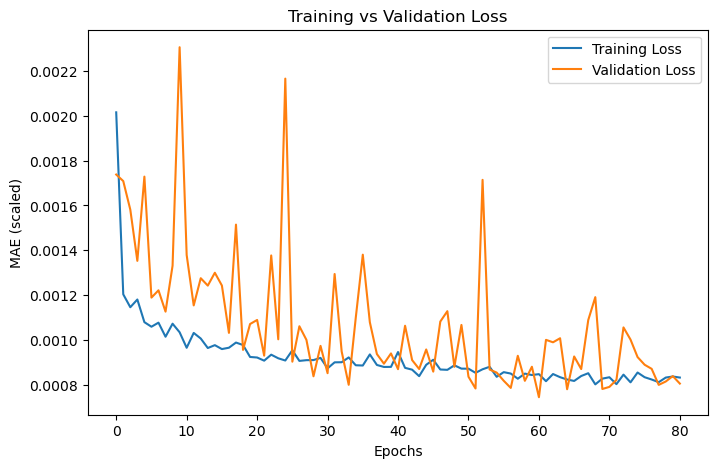

In [4]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("MAE (scaled)")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =============================
# 1. Select a single day for plotting
# =============================
start_idx = 110                # start index of the day
end_idx = start_idx + 144 +150   # one day = 144 samples (10-min intervals)

y_test_day = y_actual[start_idx:end_idx]
y_pred_day = y_final[start_idx:end_idx]

# =============================
# 2. Confidence levels
# =============================
conf_levels = [0.95, 0.9, 0.8, 0.7, 0.6]

# =============================
# 3. Quantile-based intervals (tight, for metrics)
# =============================
intervals = {}
for cl in conf_levels:
    q = np.quantile(np.abs(y_test_day - y_pred_day), cl)
    L = y_pred_day - q
    U = y_pred_day + q
    intervals[cl] = (L, U)  # for metrics

# =============================
# 4. Widen intervals for visualization (optional)
# =============================
width_factor = 3.0
intervals_day = {}
for cl in conf_levels:
    L, U = intervals[cl]
    lower_wide = y_pred_day - (y_pred_day - L) * width_factor
    upper_wide = y_pred_day + (U - y_pred_day) * width_factor
    intervals_day[cl] = (lower_wide, upper_wide)  # only for plotting

# =============================
# 5. Metrics functions
# =============================
def picp(y_true, L, U):
    return np.mean((y_true >= L) & (y_true <= U))

def pinaw(L, U, R=None):
    R = R if R is not None else (np.max(y_test_day) - np.min(y_test_day))
    return np.mean(U - L) / R

def awd(y_true, L, U):
    awd_i = np.zeros_like(y_true)
    awd_i[y_true < L] = (L[y_true < L] - y_true[y_true < L]) / (U[y_true < L] - L[y_true < L])
    awd_i[y_true > U] = (y_true[y_true > U] - U[y_true > U]) / (U[y_true > U] - L[y_true > U])
    return np.mean(awd_i)


# =============================
# 7. Metrics table (tight intervals)
# =============================
results = []
for cl in conf_levels:
    L, U = intervals[cl]  # use tight intervals for metrics
    picp_val = picp(y_test_day, L, U)
    pinaw_val = pinaw(L, U)
    awd_val = awd(y_test_day, L, U)
    ace_val = abs(picp_val - cl)  # only ACE is absolute
    results.append([f"{int(cl*100)}%", picp_val*100, pinaw_val, awd_val, ace_val*100])

df_results = pd.DataFrame(results, columns=["Interval", "PICP (%)", "PINAW", "AWD", "ACE (%)"])
print(df_results)


  Interval   PICP (%)     PINAW       AWD   ACE (%)
0      95%  94.897959  0.034557  0.016970  0.102041
1      90%  89.795918  0.025126  0.038498  0.204082
2      80%  79.931973  0.015349  0.107889  0.068027
3      70%  70.068027  0.011930  0.174970  0.068027
4      60%  59.863946  0.009421  0.268279  0.136054


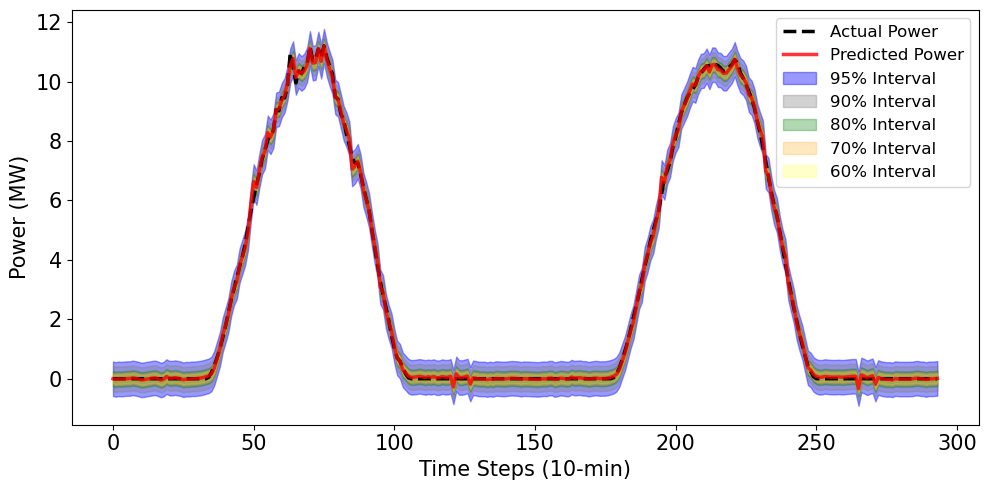

In [6]:
# =============================
# 6. Plotting
# =============================
fig, ax = plt.subplots(figsize=(10,5))

# Set axes background color to sky blue with alpha
#ax.set_facecolor((0.53, 0.81, 0.92, 0.3))  # RGB normalized + alpha

# Actual and predicted
ax.plot(y_test_day, label="Actual Power", color="black", linestyle='--', linewidth=2.5)
ax.plot(y_pred_day, label="Predicted Power", color="red", linewidth=2.5, alpha=0.8)

# Colors and alpha for CI fan
colors = {0.95: "blue", 0.9: "gray", 0.8: "green", 0.7: "orange", 0.6: "yellow"}
alphas = {0.95: 0.4, 0.9: 0.35, 0.8: 0.3, 0.7: 0.25, 0.6: 0.2}

# Plot CI bands from widest to narrowest
for cl in sorted(conf_levels, reverse=True):
    L, U = intervals_day[cl]
    ax.fill_between(range(len(y_test_day)), L, U, color=colors[cl], alpha=alphas[cl],
                    label=f"{int(cl*100)}% Interval")

ax.set_xlabel("Time Steps (10-min)", fontsize=15)
ax.set_ylabel("Power (MW)", fontsize=15)
ax.tick_params(axis='both', labelsize=15)
ax.legend(fontsize=12)
plt.tight_layout()
#plt.savefig("/mnt/f/Solar-Review-Ppaer/Result/power_prediction.png", dpi=300, bbox_inches='tight')  

plt.show()
